In [4]:
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder

In [ ]:
def FindSource(hdu):
    """
    Find the centre of the brightest source in an image
    """

    # Taking the data and conversion factor between image and detector coords
    data = hdu.data
    factor = hdu.header["CDELT1L"]

    # Detecting sources
    mean, median, std = sigma_clipped_stats(data, sigma=3.0)
    daofind = DAOStarFinder(fwhm=3.0, threshold=1*std)
    sources = daofind(data - median)

    # Taking the brightest source detected
    source = sources[sources["mag"] == sources["mag"].min()]

    source = np.array([source["x_centroid"].data[0], source["y_centroid"].data[0]])

    return source, factor

def PlotSelection(hdu, source):
    """
    Plot the image and detected centre
    """

    fig, ax = plt.subplots()

    # Plotting the image
    ax.imshow(hdu.data, origin='lower', norm=LogNorm(), cmap="plasma")

    # Cropping to the small window
    ax.set_xlim(250, 350)
    ax.set_ylim(250, 350)

    # Plotting a crosshair for the detection
    ax.vlines([source[0]/hdu.header["CDELT1L"]], ymin=250, ymax=350, color="black")
    ax.hlines([source[1]/hdu.header["CDELT1L"]], xmin=250, xmax=350, color="black")

    # Removing ticks
    ax.set_xticks([])
    ax.set_yticks([])

    return fig, ax

(<Figure size 640x480 with 1 Axes>, <Axes: >)

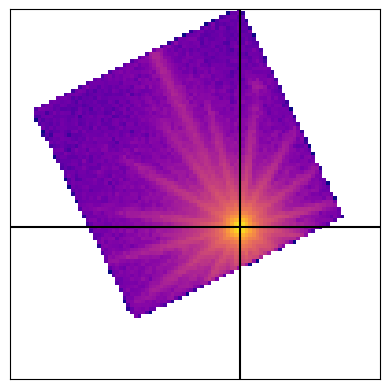

In [8]:
# Opening the file
hdu = fits.open("data/pn-all.fits")[0]

# Finding the source
source, factor = FindSource(hdu)

# Plotting the detection
PlotSelection(hdu, source*factor)